In [1]:
import requests
import apimoex
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def load_close(ticker, start="2020-01-01", end="2025-12-31"):
    with requests.Session() as s:
        data = apimoex.get_board_history(s, ticker, start=start, end=end)
    df = pd.DataFrame(data)[["TRADEDATE", "CLOSE"]]
    df["TRADEDATE"] = pd.to_datetime(df["TRADEDATE"])
    return df.set_index("TRADEDATE")["CLOSE"].rename(ticker)

A, B = "SBER", "GAZP"
prices = pd.concat([load_close(A), load_close(B)], axis=1, join="inner")
prices.tail()

,SBER,GAZP
TRADEDATE,,
2025-12-24,302.03,125.04
2025-12-25,300.26,124.20
2025-12-26,302.51,127.37
2025-12-29,299.70,125.29
2025-12-30,299.90,125.36


In [3]:
R = prices.dropna().pct_change().dropna()
print(len(R), "торговых дней")
R.describe()

1502 торговых дней


,SBER,GAZP
count,1502.000000,1502.000000
mean,0.000382,-0.000159
std,0.022711,0.025039
min,-0.366134,-0.304552
25%,-0.007936,-0.010079
50%,0.000480,-0.000692
75%,0.009473,0.009656
max,0.128986,0.249510


In [4]:
def var_hist(L, a):
    return np.quantile(L, a, method="inverted_cdf")

def es_hist(L, a):
    L = np.asarray(L); v = var_hist(L, a); n = len(L)
    return (L[L > v].sum() / n + v * (np.mean(L <= v) - a)) / (1 - a)

test = [-4, -2, -1, 0, 0, 1, 2, 3, 5, 11]
print(var_hist(test, 0.8), round(es_hist(test, 0.8), 10))

3 8.0


In [5]:
def portfolio_loss(R, x):
    return -(x * R[A] + (1 - x) * R[B])

mA, mB = R[A].mean(), R[B].mean()
sA, sB = R[A].std(), R[B].std()
rho_hat = R[A].corr(R[B])

def var_es_normal(x, a, rho=rho_hat):
    mu = -(x * mA + (1 - x) * mB)
    s = np.sqrt(x**2 * sA**2 + (1 - x)**2 * sB**2 + 2 * x * (1 - x) * rho * sA * sB)
    z = norm.ppf(a)
    return mu + s * z, mu + s * norm.pdf(z) / (1 - a)

alphas = [0.95, 0.99]
x = 0.5
L = portfolio_loss(R, x)
print(f"оценённая корреляция ρ = {rho_hat:.2f}")

table = pd.DataFrame(
    [[var_hist(L, a), es_hist(L, a), *var_es_normal(x, a)] for a in alphas],
    index=[f"{a:.0%}" for a in alphas],
    columns=["VaR исторический", "ES исторический", "VaR нормальный", "ES нормальный"],
)
table.map(lambda v: f"{v:.2%}")

оценённая корреляция ρ = 0.61


,VaR исторический,ES исторический,VaR нормальный,ES нормальный
95%,2.69%,5.02%,3.51%,4.41%
99%,5.39%,10.31%,4.97%,5.70%


In [6]:
for a in alphas:
    for xx in [0, 0.5, 1]:
        Lx = portfolio_loss(R, xx)
        assert var_hist(Lx, a) <= es_hist(Lx, a) <= Lx.max() + 1e-12
    assert np.isclose(var_hist(portfolio_loss(R, 1), a), var_hist(-R[A], a))
print("проверки пройдены")

проверки пройдены


In [7]:
L.sort_values(ascending=False).head(10).to_frame("убыток портфеля 50/50")

,убыток портфеля 50/50
TRADEDATE,
2022-02-24,0.312710
2022-02-21,0.182752
2022-06-30,0.180891
2022-09-20,0.094084
2022-09-26,0.093534
2020-03-10,0.088571
2022-01-18,0.085492
2022-03-25,0.078341
2022-10-07,0.072735


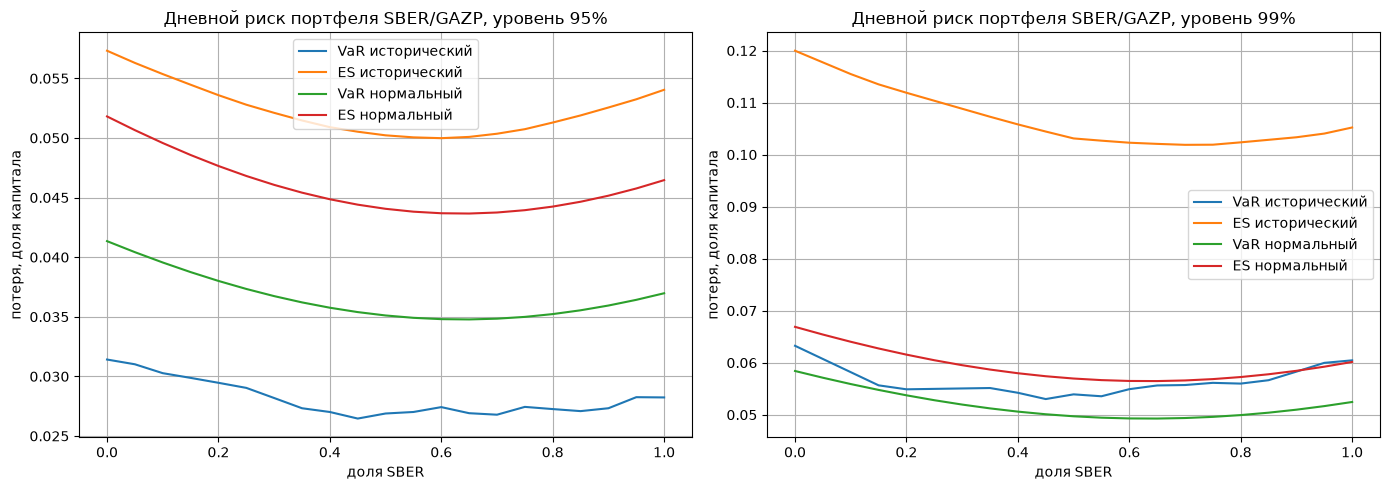

In [8]:
xs = np.linspace(0, 1, 21)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, a in zip(axes, alphas):
    res = pd.DataFrame({
        "VaR исторический": [var_hist(portfolio_loss(R, x), a) for x in xs],
        "ES исторический":  [es_hist(portfolio_loss(R, x), a) for x in xs],
        "VaR нормальный":   [var_es_normal(x, a)[0] for x in xs],
        "ES нормальный":    [var_es_normal(x, a)[1] for x in xs],
    }, index=xs)
    res.plot(ax=ax, title=f"Дневной риск портфеля {A}/{B}, уровень {a:.0%}")
    ax.set_xlabel(f"доля {A}"); ax.set_ylabel("потеря, доля капитала"); ax.grid()
plt.tight_layout()
plt.show()

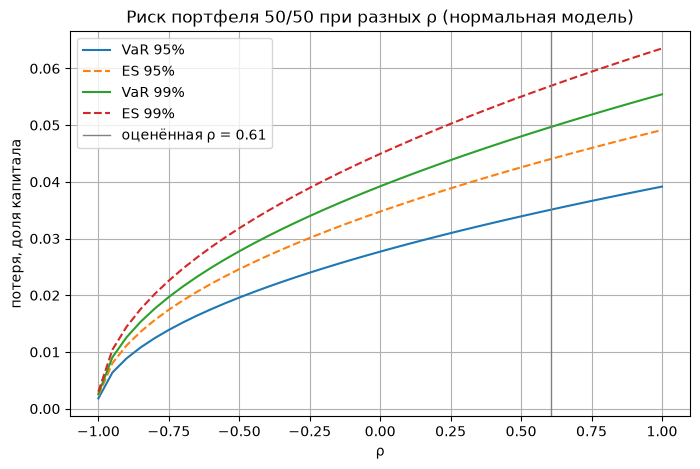

In [9]:
rhos = np.linspace(-1, 1, 41)
plt.figure(figsize=(8, 5))
for a in alphas:
    plt.plot(rhos, [var_es_normal(0.5, a, r)[0] for r in rhos], label=f"VaR {a:.0%}")
    plt.plot(rhos, [var_es_normal(0.5, a, r)[1] for r in rhos], label=f"ES {a:.0%}", ls="--")
plt.axvline(rho_hat, color="gray", lw=1, label=f"оценённая ρ = {rho_hat:.2f}")
plt.title("Риск портфеля 50/50 при разных ρ (нормальная модель)")
plt.xlabel("ρ"); plt.ylabel("потеря, доля капитала"); plt.legend(); plt.grid()
plt.show()